In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score
from sklearn.metrics import auc
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

print(df.shape)
df.head()
df.isnull().sum()
target = "converted"
numerical = [c for c in df.columns
             if c != target and pd.api.types.is_numeric_dtype(df[c])]
categorical = [c for c in df.columns
               if c != target and c not in numerical]

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

(5000, 9)


In [2]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [3]:
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

df_train = df_train.drop(columns=[target])
df_val = df_val.drop(columns=[target])
df_test = df_test.drop(columns=[target])


In [4]:
# q1
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_val, -df_val[col])
    print(col, round(auc, 4))

annual_income 0.6082
number_of_courses_viewed 0.723
interaction_count 0.7649
lead_score 0.7882


In [5]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [6]:
from sklearn.linear_model import LogisticRegression

In [7]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [8]:
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [9]:
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

In [10]:
#Q2
print('AUC:', round(auc, 3))

AUC: 0.732


Q3 - Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


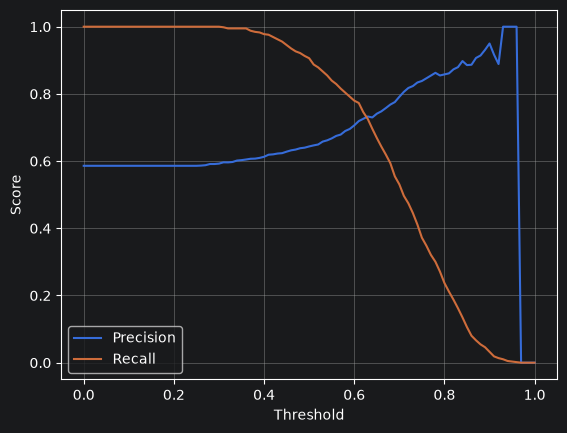

Q4 - Threshold: 0.41000000000000003


In [11]:
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    y_pred_bin = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_bin, zero_division=0)
    r = recall_score(y_val, y_pred_bin, zero_division=0)

    precisions.append(p)
    recalls.append(r)

    f1 = 2 * p * r / (p + r) if p + r > 0 else 0
    f1_scores.append(f1)

# Q3: menor diferença entre precision e recall,
# ignorando os limiares em que ambas são zero
differences = [
    abs(p - r) if p != 0 or r != 0 else np.inf
    for p, r in zip(precisions, recalls)
]

idx_intersection = np.argmin(differences)
print("Q3 - Threshold:", thresholds[idx_intersection])
print("Precision:", precisions[idx_intersection])
print("Recall:", recalls[idx_intersection])

# Gráfico
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

# Q4: threshold que maximiza F1
idx_f1 = np.argmax(f1_scores)
print("Q4 - Threshold:", thresholds[idx_f1])

In [12]:
def train_and_evaluate(df_train, df_val, C=1.0):
    y_train = df_train[target].values
    y_val = df_val[target].values

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train.drop(columns=target).to_dict('records'))
    X_val = dv.transform(df_val.drop(columns=target).to_dict('records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
kf = KFold(n_splits=5, shuffle=True, random_state=1)

# Q5
scores = []

for train_idx, val_idx in kf.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    auc = train_and_evaluate(df_train_fold, df_val_fold, C=1.0)
    scores.append(auc)

print("Q5 - Scores:", np.round(scores, 3))
print("Q5 - Standard deviation:", round(np.std(scores), 3))

# Q6
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        auc = train_and_evaluate(df_train_fold, df_val_fold, C=C)
        scores.append(auc)

    print(
        f"C={C}: mean={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )

Q5 - Scores: [0.731 0.73  0.736 0.741 0.721]
Q5 - Standard deviation: 0.007
C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
